# Classification de la qualité du vin

**Projet Machine Learning 1 — EFREI ING2-BDML — 2026-2027**

**Objectif** : prédire si un vin est **bon** (`quality >= 7`) ou non à partir de 11 mesures physicochimiques.

**Données** : *Wine Quality* (vinho verde) — 1599 vins rouges et 4898 vins blancs.

**Plan** : 1. Chargement · 2. Nettoyage · 3. Cible et classes · 4. Visualisations · 5. Découpage train/test · 6. Sélection de variables · 7. Modèles · 8. Biais/variance · 9. Hyperparamètres · 10. Seuil · 11. Test final · 12. Interprétation · 13. Sauvegarde

## 1. Chargement des données

In [1]:
import warnings; warnings.filterwarnings("ignore")
import time
import zipfile
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import loguniform
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import RFE, SelectKBest, f_classif, mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    classification_report,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    RandomizedSearchCV,
    StratifiedKFold,
    cross_val_predict,
    cross_val_score,
    cross_validate,
    learning_curve,
    train_test_split,
)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42          # pour obtenir toujours les mêmes résultats
sns.set_theme(style="whitegrid")



In [2]:
# Les fichiers utilisent le point-virgule comme séparateur
rouge = pd.read_csv( "../data/winequality-red.csv", sep=";")
blanc = pd.read_csv( "../data/winequality-white.csv", sep=";")

# Seule variable catégorielle : le type de vin (0 = rouge, 1 = blanc)
rouge["type"] = 0
blanc["type"] = 1

df_brut = pd.concat([rouge, blanc], ignore_index=True)
print("rouge :", rouge.shape, "| blanc :", blanc.shape, "| fusionné :", df_brut.shape)
display(df_brut.head())

rouge : (1599, 13) | blanc : (4898, 13) | fusionné : (6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0


In [3]:
df_brut.info()
print("Valeurs manquantes :", df_brut.isna().sum().sum())
print("Lignes dupliquées  :", df_brut.duplicated().sum())
display(df_brut.describe().T.round(3))

<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  type                  6497 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 660.0 KB
Valeurs manquantes : 0
Lignes dupliquées  : 1177


,count,mean,std,min,25%,50%,75%,max
fixed acidity,6497.0,7.215,1.296,3.800,6.400,7.000,7.700,15.900
volatile acidity,6497.0,0.340,0.165,0.080,0.230,0.290,0.400,1.580
citric acid,6497.0,0.319,0.145,0.000,0.250,0.310,0.390,1.660
residual sugar,6497.0,5.443,4.758,0.600,1.800,3.000,8.100,65.800
chlorides,6497.0,0.056,0.035,0.009,0.038,0.047,0.065,0.611
free sulfur dioxide,6497.0,30.525,17.749,1.000,17.000,29.000,41.000,289.000
total sulfur dioxide,6497.0,115.745,56.522,6.000,77.000,118.000,156.000,440.000
density,6497.0,0.995,0.003,0.987,0.992,0.995,0.997,1.039
pH,6497.0,3.219,0.161,2.720,3.110,3.210,3.320,4.010
sulphates,6497.0,0.531,0.149,0.220,0.430,0.510,0.600,2.000


**Constats** : aucune valeur manquante, une seule variable catégorielle (`type`), des échelles très différentes (il faudra standardiser) et beaucoup de doublons.

## 2. Nettoyage : doublons et valeurs aberrantes

In [4]:
nb_doublons = df_brut.duplicated().sum()
print(f"{nb_doublons} doublons sur {len(df_brut)} lignes ({nb_doublons / len(df_brut):.1%})")

# On supprime les doublons : une même ligne en train ET en test fausserait les scores
df = df_brut.drop_duplicates().reset_index(drop=True)
print("Après suppression :", df.shape)

1177 doublons sur 6497 lignes (18.1%)
Après suppression : (5320, 13)


In [5]:
variables = [c for c in df.columns if c != "quality"]      # 11 mesures + type
mesures = [c for c in variables if c != "type"]             # les 11 mesures continues

# Valeurs aberrantes : règle de l'IQR (au-delà de 1,5 x IQR des quartiles)
lignes = []
for col in mesures:
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    nb = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    lignes.append({"variable": col, "outliers_IQR": nb, "asymétrie": round(df[col].skew(), 2)})

display(pd.DataFrame(lignes).set_index("variable").sort_values("outliers_IQR", ascending=False))

,outliers_IQR,asymétrie
variable,,
fixed acidity,304,1.65
volatile acidity,279,1.50
chlorides,237,5.34
sulphates,163,1.81
citric acid,143,0.48
residual sugar,141,1.71
pH,49,0.39
free sulfur dioxide,44,1.36
total sulfur dioxide,10,0.06


**Décision** : on **garde** ces points extrêmes. Ce sont des vins réels (un vin très sucré existe), pas des erreurs de mesure. On limite leur influence avec la standardisation et avec des modèles robustes (arbres).

## 3. Cible binaire et équilibre des classes

good
0    4311
1    1009
Name: count, dtype: int64
good
0    0.81
1    0.19
Name: proportion, dtype: float64

Part de bons vins par type :
type
blanc    0.208
rouge    0.135
Name: good, dtype: float64


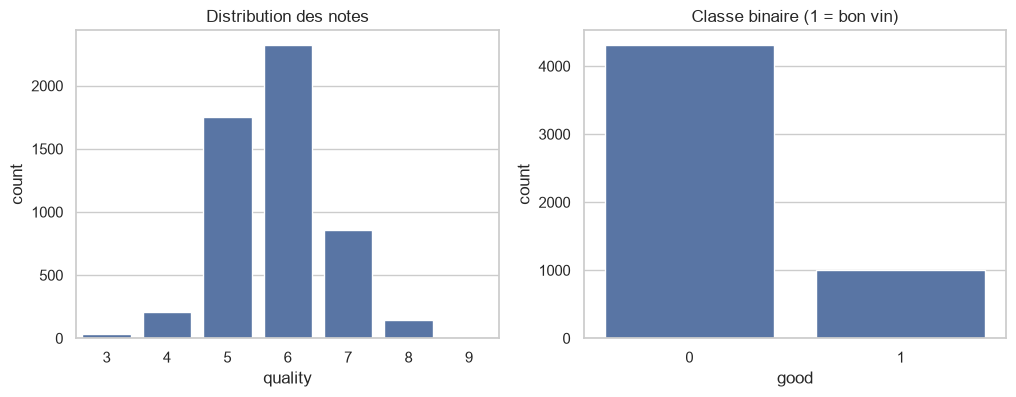

Accuracy d'un modèle qui répond toujours 'pas bon' : 0.810


In [6]:
df["good"] = (df["quality"] >= 7).astype(int)      # 1 = bon vin, 0 = pas bon

print(df["good"].value_counts())
print(df["good"].value_counts(normalize=True).round(3))
print()
print("Part de bons vins par type :")
print(df.groupby(df["type"].map({0: "rouge", 1: "blanc"}))["good"].mean().round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x="quality", data=df, ax=ax[0]); ax[0].set_title("Distribution des notes")
sns.countplot(x="good", data=df, ax=ax[1]); ax[1].set_title("Classe binaire (1 = bon vin)")
plt.show()

acc_reference = 1 - df["good"].mean()
print(f"Accuracy d'un modèle qui répond toujours 'pas bon' : {acc_reference:.3f}")

**Lecture** : seulement 19 % de bons vins. Un modèle qui répond toujours « pas bon » a déjà environ 81 % d'accuracy, donc **l'accuracy est trompeuse**. On utilisera surtout précision, rappel, F1 et AUC, avec un découpage stratifié et `class_weight="balanced"`.

## 4. Visualisations et corrélations

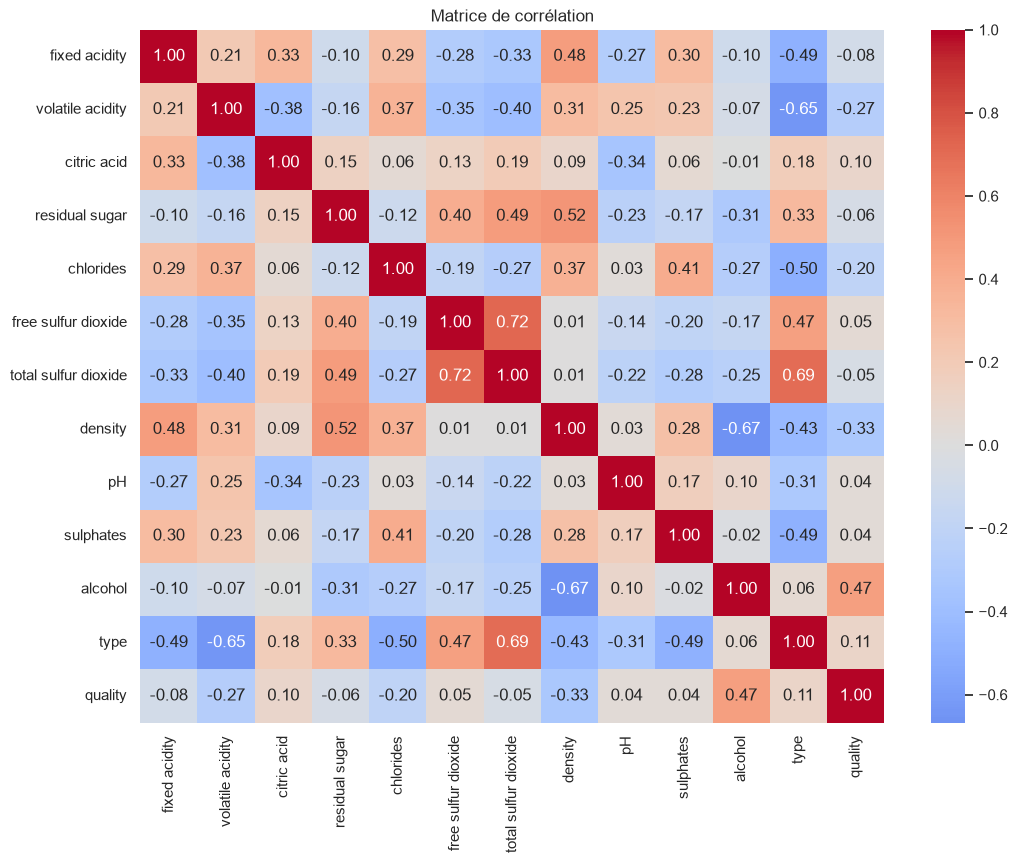

Corrélation avec la note :
density                -0.33
volatile acidity       -0.27
chlorides              -0.20
fixed acidity          -0.08
residual sugar         -0.06
total sulfur dioxide   -0.05
pH                      0.04
sulphates               0.04
free sulfur dioxide     0.05
citric acid             0.10
type                    0.11
alcohol                 0.47
dtype: float64

Paires les plus corrélées (valeur absolue) :
free sulfur dioxide  total sulfur dioxide    0.72
density              alcohol                 0.67
residual sugar       density                 0.52
                     total sulfur dioxide    0.49
fixed acidity        density                 0.48
chlorides            sulphates               0.41
dtype: float64


In [7]:
plt.figure(figsize=(12, 9))
sns.heatmap(df[variables + ["quality"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matrice de corrélation")
plt.show()

print("Corrélation avec la note :")
print(df[variables].corrwith(df["quality"]).sort_values().round(2))

# Paires de variables les plus corrélées entre elles
corr = df[mesures].corr().abs()
paires = corr.where(np.triu(np.ones(corr.shape), k=1) == 1).stack().sort_values(ascending=False)
print("\nPaires les plus corrélées (valeur absolue) :")
print(paires.head(6).round(2))

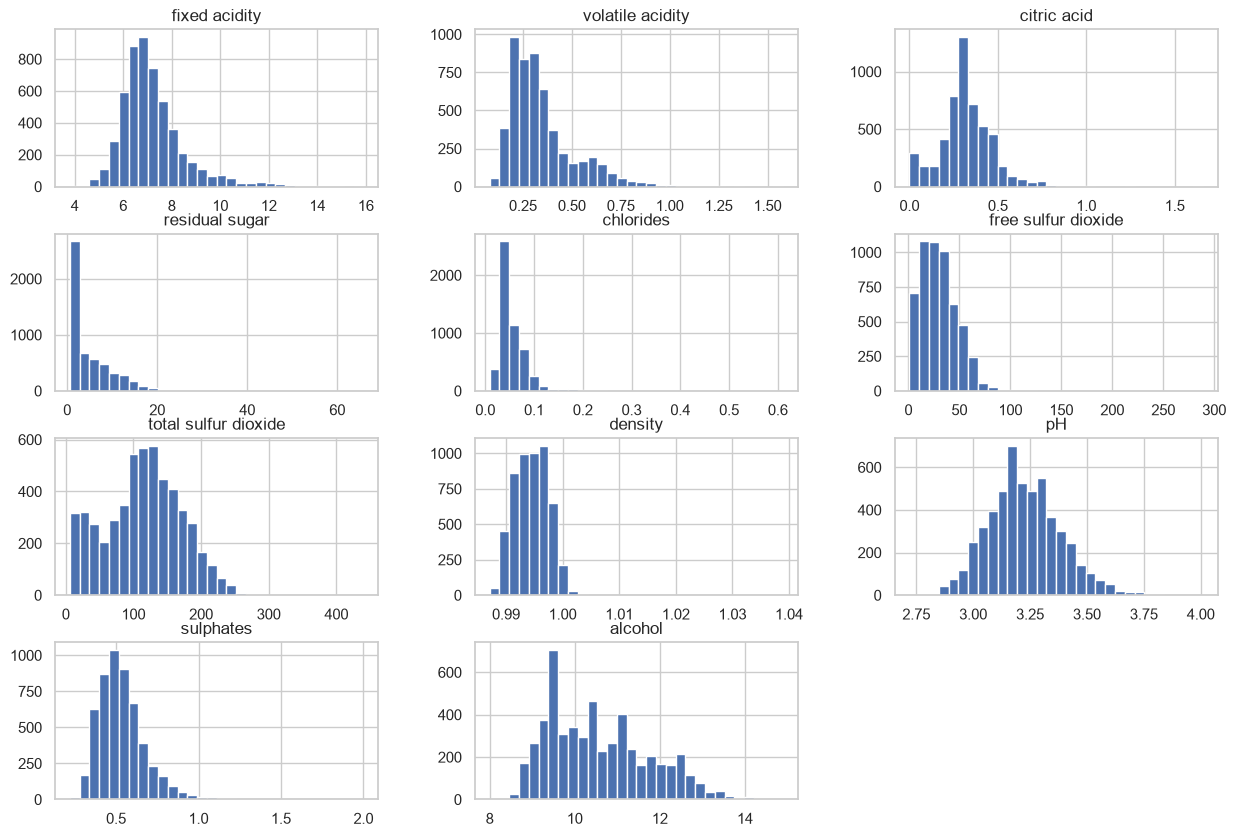

In [8]:
df[mesures].hist(bins=30, figsize=(15, 10))
plt.show()

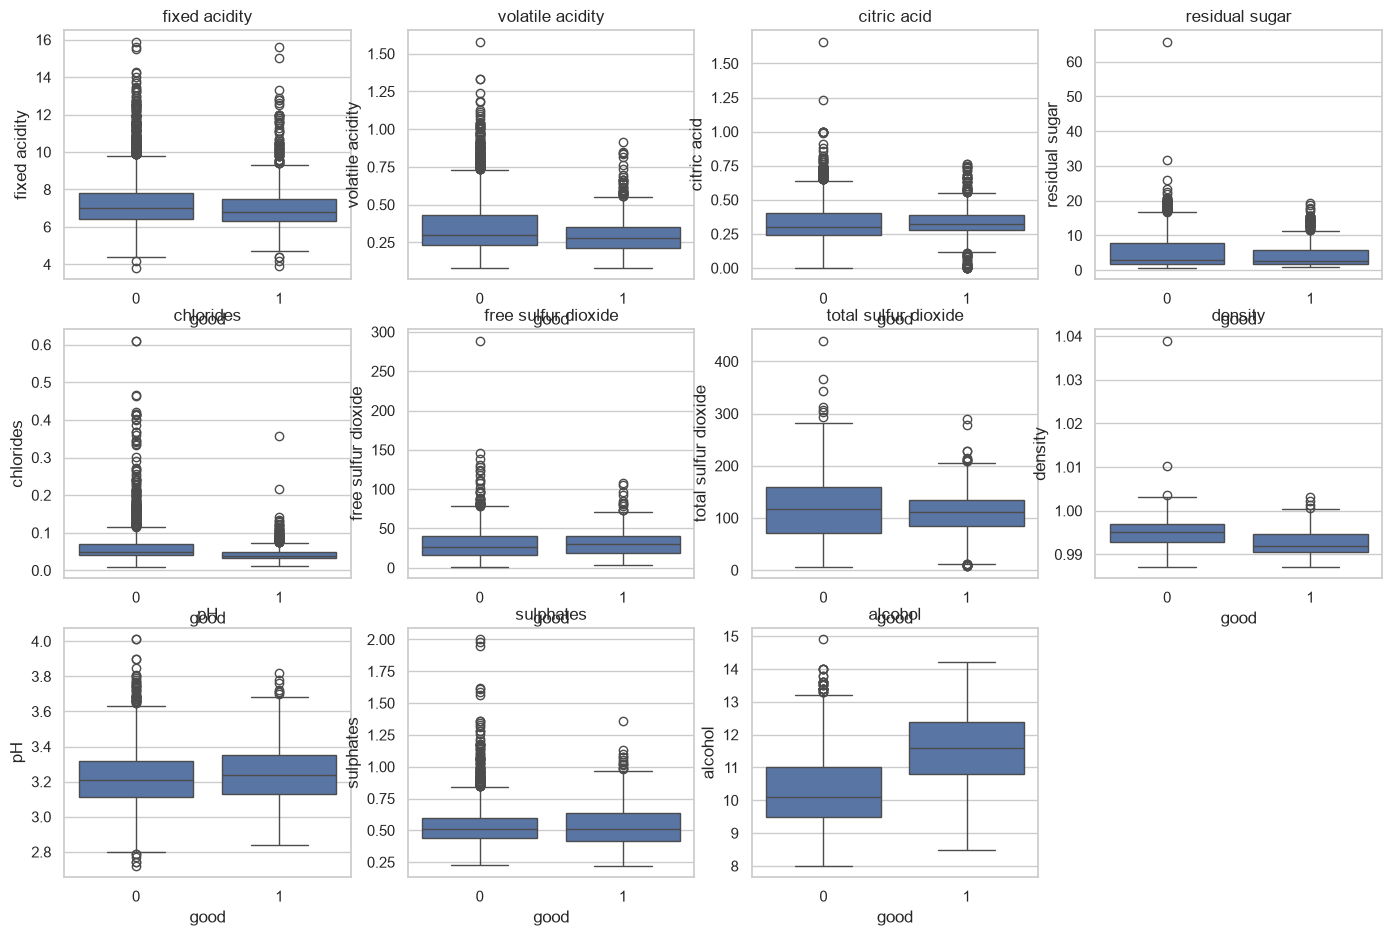

In [9]:
fig, axes = plt.subplots(3, 4, figsize=(17, 11))
for ax, col in zip(axes.ravel(), mesures):
    sns.boxplot(x="good", y=col, data=df, ax=ax)
    ax.set_title(col)
axes.ravel()[-1].axis("off")
plt.show()

**À retenir** : l'**alcool** est la variable la plus liée à la qualité (+0,47). `density` et `volatile acidity` ont un lien négatif. Certaines variables sont très corrélées entre elles (`free` / `total sulfur dioxide`, `density` / `alcohol`) : c'est un argument pour la sélection de variables et une limite pour Naive Bayes.

## 5. Découpage train / test

In [10]:
X = df[variables]
y = df["good"]

# Découpage stratifié : même proportion de bons vins dans le train et dans le test.
# Le test ne sera utilisé qu'une seule fois, à l'étape 11.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("train :", X_train.shape, "| part de bons vins :", round(y_train.mean(), 3))
print("test  :", X_test.shape, "| part de bons vins :", round(y_test.mean(), 3))

# Validation croisée utilisée partout : 5 plis stratifiés
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

train : (4256, 12) | part de bons vins : 0.19
test  : (1064, 12) | part de bons vins : 0.19


## 6. Sélection de variables

Trois familles de méthodes, calculées **sur le train uniquement** :

| Famille | Méthode |
|---|---|
| Filtre | score F (ANOVA) et information mutuelle |
| Wrapper | RFE avec régression logistique |
| Embedded | importance d'une Random Forest |

In [11]:
X_scaled = StandardScaler().fit_transform(X_train)

f_scores, _ = f_classif(X_train, y_train)                                  # filtre
info_mutuelle = mutual_info_classif(X_train, y_train, random_state=RANDOM_STATE)

rfe = RFE(LogisticRegression(max_iter=1000, class_weight="balanced"), n_features_to_select=1)
rfe.fit(X_scaled, y_train)                                                 # wrapper

foret = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE)
foret.fit(X_train, y_train)                                                # embedded

tableau = pd.DataFrame({"F_score": f_scores, "info_mutuelle": info_mutuelle,
                        "RFE_rang": rfe.ranking_, "importance_RF": foret.feature_importances_},
                       index=variables)

# Rang moyen sur les 4 critères (1 = meilleure variable)
rangs = pd.DataFrame({"F": tableau["F_score"].rank(ascending=False),
                      "MI": tableau["info_mutuelle"].rank(ascending=False),
                      "RFE": tableau["RFE_rang"],
                      "RF": tableau["importance_RF"].rank(ascending=False)})
tableau["rang_moyen"] = rangs.mean(axis=1)
display(tableau.sort_values("rang_moyen").round(3))

,F_score,info_mutuelle,RFE_rang,importance_RF,rang_moyen
alcohol,924.874,0.099,1,0.198,1.00
density,413.612,0.058,5,0.123,2.75
volatile acidity,88.489,0.026,2,0.085,3.50
chlorides,109.881,0.048,10,0.089,4.75
total sulfur dioxide,23.487,0.024,8,0.082,6.50
residual sugar,31.511,0.008,6,0.071,6.75
citric acid,14.415,0.025,12,0.077,7.75
sulphates,6.281,0.012,7,0.075,8.00
pH,7.349,0.007,4,0.067,8.25
fixed acidity,7.735,0.006,3,0.061,8.25


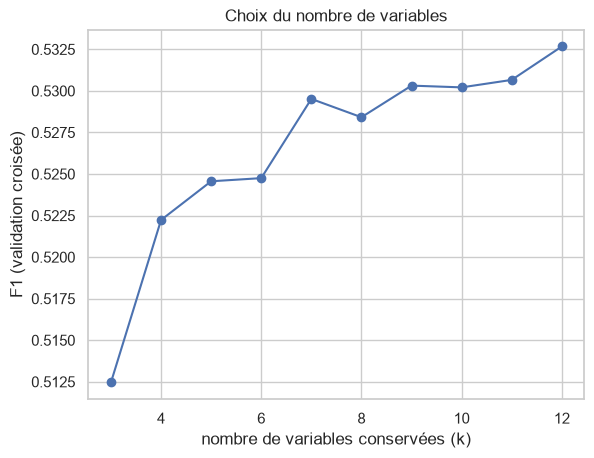

{3: np.float64(0.512), 4: np.float64(0.522), 5: np.float64(0.525), 6: np.float64(0.525), 7: np.float64(0.53), 8: np.float64(0.528), 9: np.float64(0.53), 10: np.float64(0.53), 11: np.float64(0.531), 12: np.float64(0.533)}


In [12]:
# Combien de variables garder ? On teste k = 3 à 12 (la sélection est refaite dans chaque pli)
valeurs_k = list(range(3, len(variables) + 1))
scores_k = []
for k in valeurs_k:
    pipe = Pipeline([("scaler", StandardScaler()),
                     ("select", SelectKBest(f_classif, k=k)),
                     ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))])
    scores_k.append(cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1").mean())

plt.plot(valeurs_k, scores_k, marker="o")
plt.xlabel("nombre de variables conservées (k)"); plt.ylabel("F1 (validation croisée)")
plt.title("Choix du nombre de variables")
plt.show()
print({k: round(s, 3) for k, s in zip(valeurs_k, scores_k)})

**Lecture** : l'alcool, la densité et l'acidité volatile sont en tête pour presque toutes les méthodes. Le F1 varie très peu avec k : avec seulement 12 variables, la sélection sert surtout à comprendre les données.

**Règle d'or** : la sélection est placée **dans le `Pipeline`**, donc refaite dans chaque pli de validation croisée. Sinon, des informations du pli de validation fuiraient dans l'entraînement (fuite de données).

## 7. Modélisation et comparaison

| Modèle | Type | Intérêt / limite ici |
|---|---|---|
| Régression logistique | linéaire | simple et interprétable ; limitée si la frontière est non linéaire |
| k-NN | non linéaire (distance) | demande la standardisation ; sensible au bruit et au déséquilibre |
| Arbre de décision | non linéaire | règles lisibles, robuste aux outliers ; variance élevée |
| Naive Bayes | probabiliste | suppose des variables indépendantes : **faux ici** |
| SVM (noyau RBF) | non linéaire | bon sur variables continues et bruitées ; sensible à C et gamma |
| Random Forest | ensemble | réduit la variance, donne l'importance des variables |

Le déséquilibre est géré par `class_weight="balanced"` (k-NN et Naive Bayes n'ont pas ce paramètre).

In [13]:
def creer_pipeline(modele, k=8):
    """Standardisation -> sélection des k meilleures variables -> modèle."""
    return Pipeline([("scaler", StandardScaler()),
                     ("select", SelectKBest(f_classif, k=k)),
                     ("clf", modele)])

modeles = {
    "LogReg":       creer_pipeline(LogisticRegression(max_iter=1000, class_weight="balanced")),
    "kNN":          creer_pipeline(KNeighborsClassifier()),
    "Tree":         creer_pipeline(DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE)),
    "NaiveBayes":   creer_pipeline(GaussianNB()),
    "SVM":          creer_pipeline(SVC(class_weight="balanced", random_state=RANDOM_STATE)),
    "RandomForest": creer_pipeline(RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE)),
}

metriques = ["accuracy", "precision", "recall", "f1", "roc_auc"]

def evaluer(dico_modeles):
    """Validation croisée 5 plis sur le train : renvoie un tableau de métriques."""
    lignes = []
    for nom, modele in dico_modeles.items():
        res = cross_validate(modele, X_train, y_train, cv=cv, scoring=metriques,
                             return_train_score=True, n_jobs=-1)
        ligne = {"modèle": nom}
        for m in metriques:
            ligne[m] = res["test_" + m].mean()
        ligne["F1_train"] = res["train_f1"].mean()
        lignes.append(ligne)
    return pd.DataFrame(lignes).set_index("modèle").round(3)

resultats = evaluer(modeles)
print(f"Référence : un modèle 'toujours pas bon' a une accuracy de {acc_reference:.3f}")
display(resultats.sort_values("f1", ascending=False))

Référence : un modèle 'toujours pas bon' a une accuracy de 0.810


,accuracy,precision,recall,f1,roc_auc,F1_train
modèle,,,,,,
RandomForest,0.813,0.508,0.555,0.530,0.830,0.993
LogReg,0.735,0.399,0.783,0.528,0.816,0.527
SVM,0.721,0.387,0.803,0.522,0.820,0.540
NaiveBayes,0.742,0.394,0.665,0.495,0.769,0.490
kNN,0.816,0.520,0.405,0.455,0.783,0.618
Tree,0.783,0.426,0.408,0.416,0.639,1.000


**Comment lire** : comparer l'accuracy à la référence de 81 % ; le **rappel** = part des vrais bons vins retrouvés ; la **précision** = part des vins annoncés bons qui le sont vraiment ; le **F1** résume les deux. L'écart entre `F1_train` et `f1` mesure la variance du modèle.

## 8. Biais / variance

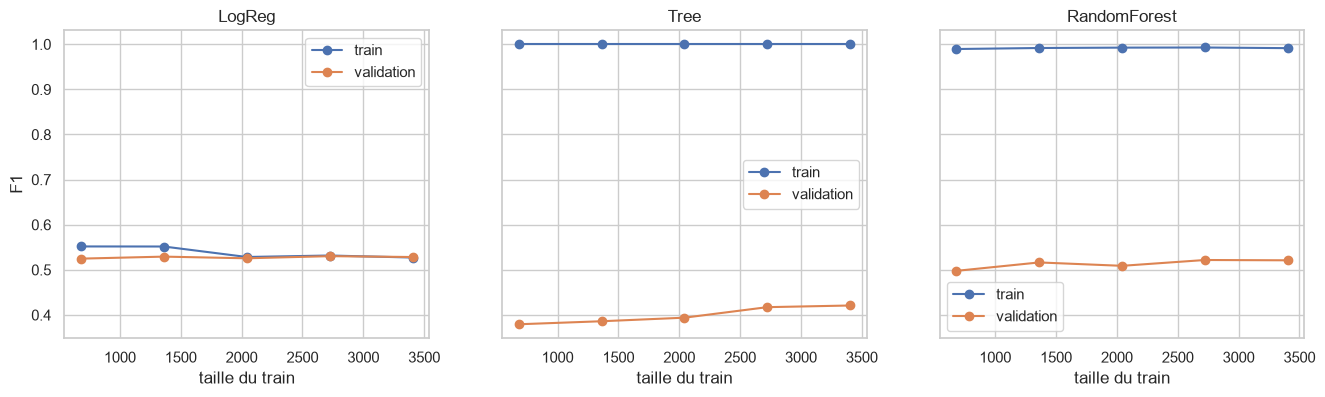

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, nom in zip(axes, ["LogReg", "Tree", "RandomForest"]):
    tailles, f1_train, f1_val = learning_curve(modeles[nom], X_train, y_train, cv=cv, scoring="f1",
                                               train_sizes=np.linspace(0.2, 1.0, 5), n_jobs=-1,
                                               random_state=RANDOM_STATE)
    ax.plot(tailles, f1_train.mean(axis=1), marker="o", label="train")
    ax.plot(tailles, f1_val.mean(axis=1), marker="o", label="validation")
    ax.set_title(nom); ax.set_xlabel("taille du train"); ax.legend()
axes[0].set_ylabel("F1")
plt.show()

| Observation | Diagnostic |
|---|---|
| Train très haut, validation bien plus bas | **variance élevée** (surapprentissage : arbre, forêt) |
| Train et validation bas et proches | **biais élevé** (modèle trop simple, ou données bruitées) |
| Train et validation hauts et proches | bon compromis |

## 9. Optimisation des hyperparamètres

- **Grid Search** : essaie toutes les combinaisons d'une grille (cinq modèles du sujet).
- **Random Search** : tire des combinaisons au hasard (SVM et Random Forest).

On optimise le **F1**, avec la validation croisée 5 plis sur le train.

In [15]:
choix_k = [8, 12]       # nombre de variables à tester
grilles = {
    "LogReg":     {"select__k": choix_k, "clf__C": [0.01, 0.1, 1, 10]},
    "kNN":        {"select__k": choix_k, "clf__n_neighbors": [3, 5, 11, 21, 31], "clf__weights": ["uniform", "distance"]},
    "Tree":       {"select__k": choix_k, "clf__max_depth": [3, 5, 8, 12, None], "clf__min_samples_leaf": [1, 5, 10, 20]},
    "NaiveBayes": {"select__k": choix_k, "clf__var_smoothing": [1e-9, 1e-7, 1e-5, 1e-3, 1e-1]},
    "SVM":        {"select__k": choix_k, "clf__C": [0.1, 1, 10], "clf__gamma": ["scale", 0.1]},
}

meilleurs = {}       # meilleur modèle trouvé pour chaque recherche
recap = []           # tableau récapitulatif

for nom, grille in grilles.items():
    debut = time.time()
    recherche = GridSearchCV(modeles[nom], grille, cv=cv, scoring="f1", n_jobs=-1)
    recherche.fit(X_train, y_train)
    meilleurs[nom + " (grid)"] = recherche.best_estimator_
    recap.append({"modèle": nom, "méthode": "Grid Search", "F1_CV": round(recherche.best_score_, 3),
                  "temps_s": round(time.time() - debut, 1), "meilleurs_params": recherche.best_params_})

In [16]:
# Random Search : SVM et Random Forest
espaces = {
    "SVM": {"select__k": choix_k, "clf__C": loguniform(1e-1, 1e2), "clf__gamma": loguniform(1e-3, 1e0)},
    "RandomForest": {"select__k": choix_k, "clf__n_estimators": [100, 200, 300],
                     "clf__max_depth": [None, 5, 10, 20], "clf__min_samples_leaf": [1, 2, 5, 10]},
}
nb_tirages = {"SVM": 12, "RandomForest": 10}

for nom, espace in espaces.items():
    debut = time.time()
    recherche = RandomizedSearchCV(modeles[nom], espace, n_iter=nb_tirages[nom], cv=cv,
                                   scoring="f1", n_jobs=-1, random_state=RANDOM_STATE)
    recherche.fit(X_train, y_train)
    meilleurs[nom + " (random)"] = recherche.best_estimator_
    recap.append({"modèle": nom, "méthode": "Random Search", "F1_CV": round(recherche.best_score_, 3),
                  "temps_s": round(time.time() - debut, 1), "meilleurs_params": recherche.best_params_})

pd.set_option("display.max_colwidth", 120)
display(pd.DataFrame(recap))

,modèle,méthode,F1_CV,temps_s,meilleurs_params
0,LogReg,Grid Search,0.539,0.6,"{'clf__C': 0.01, 'select__k': 12}"
1,kNN,Grid Search,0.492,1.9,"{'clf__n_neighbors': 5, 'clf__weights': 'distance', 'select__k': 12}"
2,Tree,Grid Search,0.511,2.7,"{'clf__max_depth': 3, 'clf__min_samples_leaf': 20, 'select__k': 8}"
3,NaiveBayes,Grid Search,0.499,0.5,"{'clf__var_smoothing': 0.1, 'select__k': 12}"
4,SVM,Grid Search,0.546,10.2,"{'clf__C': 1, 'clf__gamma': 0.1, 'select__k': 12}"
5,SVM,Random Search,0.539,8.6,"{'clf__C': 83.41930294140772, 'clf__gamma': 0.004992453416923981, 'select__k': 12}"
6,RandomForest,Random Search,0.556,11.7,"{'select__k': 12, 'clf__n_estimators': 100, 'clf__min_samples_leaf': 1, 'clf__max_depth': 20}"


In [17]:
# Comparaison des modèles optimisés (validation croisée sur le train)
resultats_opt = evaluer(meilleurs)
display(resultats_opt.sort_values("f1", ascending=False))

,accuracy,precision,recall,f1,roc_auc,F1_train
modèle,,,,,,
RandomForest (random),0.824,0.534,0.581,0.556,0.847,0.987
SVM (grid),0.748,0.415,0.799,0.546,0.843,0.590
LogReg (grid),0.742,0.408,0.796,0.539,0.828,0.540
SVM (random),0.732,0.400,0.828,0.539,0.841,0.558
Tree (grid),0.723,0.384,0.762,0.511,0.798,0.528
NaiveBayes (grid),0.748,0.400,0.660,0.499,0.777,0.496
kNN (grid),0.829,0.566,0.436,0.492,0.794,1.000


**Grid vs Random** (SVM) : le Random Search donne un score proche pour un temps comparable ; sa vraie force est sur les grands espaces de paramètres (Random Forest), où une grille complète serait trop longue.

## 10. Choix du seuil de décision

Par défaut, un vin est classé « bon » si son score dépasse 0,5. Avec une classe rare, un autre seuil peut améliorer le F1. On le choisit **en validation croisée sur le train**, jamais sur le test.

Modèle retenu : RandomForest (random)
Seuil optimal : 0.428 (F1 en validation croisée = 0.563)


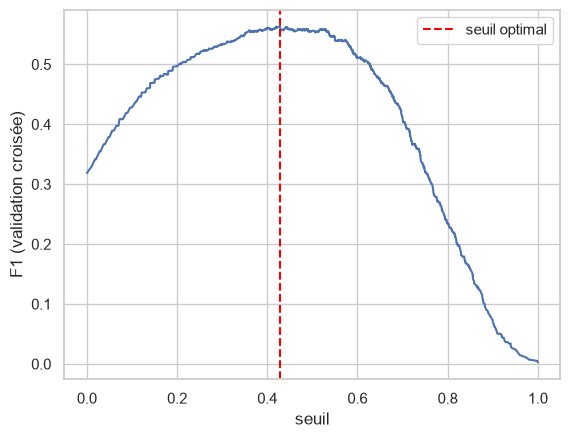

In [18]:
def calculer_scores(modele, X):
    """Score de 'bon vin' : probabilité si possible, sinon decision_function (SVM)."""
    if hasattr(modele, "predict_proba"):
        return modele.predict_proba(X)[:, 1]
    return modele.decision_function(X)

# Meilleur modèle = meilleur F1 en validation croisée
nom_final = resultats_opt["f1"].idxmax()
modele_final = meilleurs[nom_final]
print("Modèle retenu :", nom_final)

# Scores "hors pli" : chaque vin est noté par un modèle qui ne l'a pas vu
methode = "predict_proba" if hasattr(modele_final, "predict_proba") else "decision_function"
scores_cv = cross_val_predict(modele_final, X_train, y_train, cv=cv, method=methode)
if scores_cv.ndim == 2:
    scores_cv = scores_cv[:, 1]

precision, rappel, seuils = precision_recall_curve(y_train, scores_cv)
f1_seuils = 2 * precision[:-1] * rappel[:-1] / (precision[:-1] + rappel[:-1] + 1e-12)
meilleur_seuil = seuils[np.argmax(f1_seuils)]
print(f"Seuil optimal : {meilleur_seuil:.3f} (F1 en validation croisée = {f1_seuils.max():.3f})")

plt.plot(seuils, f1_seuils)
plt.axvline(meilleur_seuil, color="red", linestyle="--", label="seuil optimal")
plt.xlabel("seuil"); plt.ylabel("F1 (validation croisée)"); plt.legend()
plt.show()

## 11. Évaluation finale sur le test

⚠️ **Une seule évaluation, à la fin.** Le modèle a été choisi et réglé uniquement avec le train. Si on change quoi que ce soit après avoir vu ce résultat, ce n'est plus un vrai test.

In [19]:
scores_test = calculer_scores(modele_final, X_test)
pred_defaut = modele_final.predict(X_test)                    # seuil par défaut
pred_seuil = (scores_test >= meilleur_seuil).astype(int)      # seuil optimisé

print("=== Seuil par défaut ===")
print(classification_report(y_test, pred_defaut, target_names=["pas bon", "bon"]))
print("=== Seuil optimisé en validation croisée ===")
print(classification_report(y_test, pred_seuil, target_names=["pas bon", "bon"]))
print("AUC :", round(roc_auc_score(y_test, scores_test), 3))

=== Seuil par défaut ===
              precision    recall  f1-score   support

     pas bon       0.91      0.89      0.90       862
         bon       0.56      0.61      0.58       202

    accuracy                           0.83      1064
   macro avg       0.73      0.75      0.74      1064
weighted avg       0.84      0.83      0.84      1064

=== Seuil optimisé en validation croisée ===
              precision    recall  f1-score   support

     pas bon       0.93      0.84      0.88       862
         bon       0.52      0.74      0.61       202

    accuracy                           0.82      1064
   macro avg       0.73      0.79      0.75      1064
weighted avg       0.85      0.82      0.83      1064

AUC : 0.875


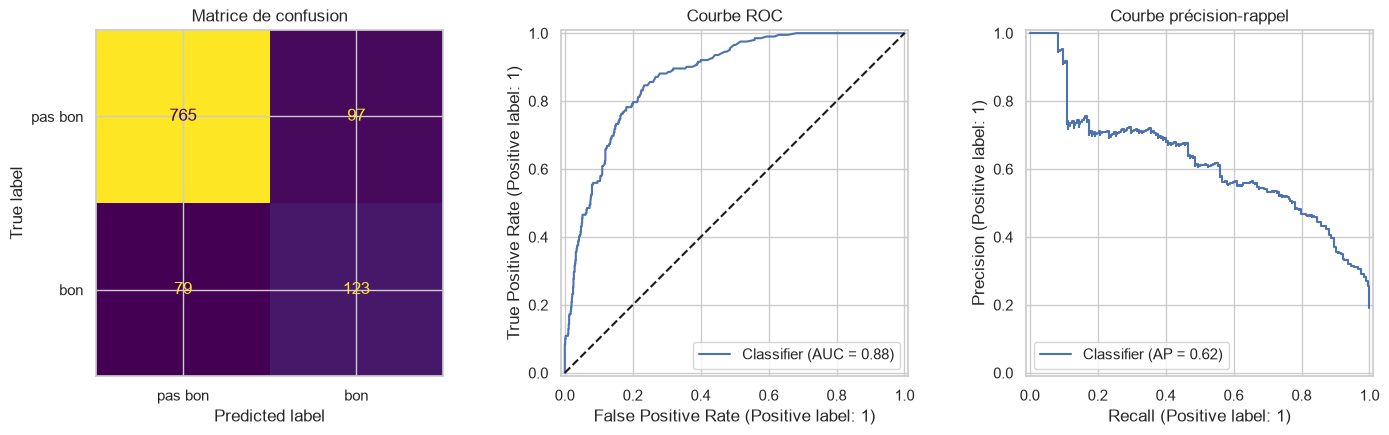

In [20]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, pred_defaut, display_labels=["pas bon", "bon"], ax=ax[0], colorbar=False)
ax[0].set_title("Matrice de confusion")
RocCurveDisplay.from_predictions(y_test, scores_test, ax=ax[1])
ax[1].plot([0, 1], [0, 1], "k--"); ax[1].set_title("Courbe ROC")
PrecisionRecallDisplay.from_predictions(y_test, scores_test, ax=ax[2])
ax[2].set_title("Courbe précision-rappel")
plt.show()

In [21]:
# Résultats séparés par type de vin
type_test = X_test["type"].map({0: "rouge", 1: "blanc"})
lignes = []
for t in ["rouge", "blanc"]:
    masque = (type_test == t).values
    lignes.append({"type": t, "vins": masque.sum(), "bons vins": y_test[masque].sum(),
                   "précision": precision_score(y_test[masque], pred_defaut[masque]),
                   "rappel": recall_score(y_test[masque], pred_defaut[masque]),
                   "F1": f1_score(y_test[masque], pred_defaut[masque])})
display(pd.DataFrame(lignes).round(3))

,type,vins,bons vins,précision,rappel,F1
0,rouge,275,37,0.568,0.568,0.568
1,blanc,789,165,0.557,0.618,0.586


**Interprétation** : pour **repérer** les bons vins, on privilégie le rappel ; pour éviter d'annoncer à tort un grand cru, la précision. Le seuil permet d'arbitrer entre les deux.

## 12. Interprétation : qu'est-ce qui fait un bon vin ?

fixed acidity           0.001
type                    0.002
residual sugar          0.010
pH                      0.021
free sulfur dioxide     0.022
citric acid             0.031
sulphates               0.033
volatile acidity        0.035
total sulfur dioxide    0.052
chlorides               0.083
density                 0.101
alcohol                 0.244
dtype: float64


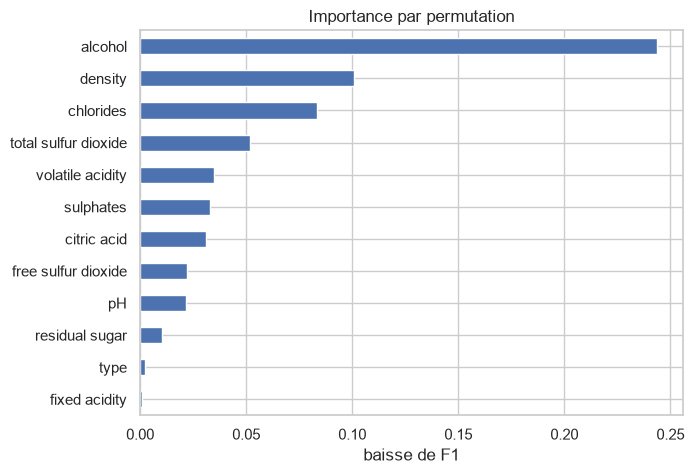

In [22]:
# Importance par permutation : baisse du F1 quand on mélange une variable
perm = permutation_importance(modele_final, X_test, y_test, scoring="f1", n_repeats=15,
                              random_state=RANDOM_STATE, n_jobs=-1)
importance = pd.Series(perm.importances_mean, index=variables).sort_values()
print(importance.round(3))

importance.plot.barh(figsize=(7, 5))
plt.title("Importance par permutation"); plt.xlabel("baisse de F1")
plt.show()

density                -1.37
volatile acidity       -0.62
total sulfur dioxide   -0.43
chlorides              -0.21
type                   -0.19
citric acid             0.01
free sulfur dioxide     0.28
sulphates               0.38
pH                      0.52
alcohol                 0.62
fixed acidity           0.78
residual sugar          0.98
dtype: float64


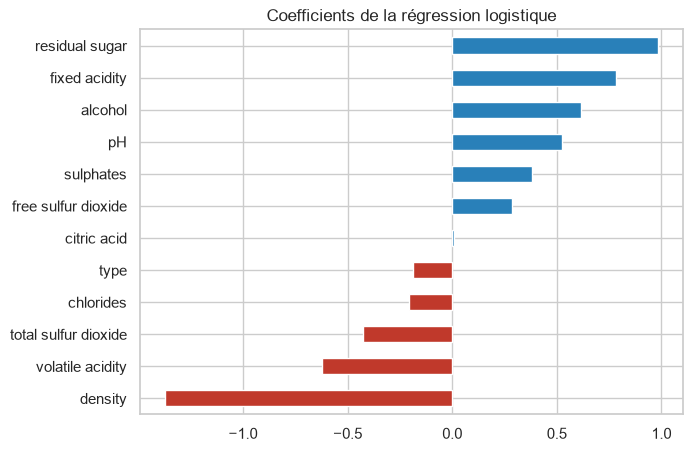

In [23]:
# Coefficients de la régression logistique (variables standardisées, donc comparables)
logreg = creer_pipeline(LogisticRegression(max_iter=1000, class_weight="balanced"), k=len(variables))
logreg.fit(X_train, y_train)
coef = pd.Series(logreg.named_steps["clf"].coef_[0], index=variables).sort_values()
print(coef.round(2))

coef.plot.barh(figsize=(7, 5), color=["#c0392b" if c < 0 else "#2980b9" for c in coef])
plt.title("Coefficients de la régression logistique")
plt.show()

**À retenir** : l'importance par permutation montre que l'**alcool** domine largement (baisse de F1 d'environ 0,21 quand on le mélange, contre 0,03 au plus pour les autres). Pour la régression logistique, un coefficient positif augmente la probabilité d'être un bon vin, un coefficient négatif la diminue : la densité (-1,37) et l'acidité volatile (-0,62) sont défavorables. **Attention** : `density` dépend de `alcohol` et `residual sugar`, donc certains coefficients (comme `residual sugar`) sont à lire avec prudence à cause de la corrélation entre variables.

## 13. Sauvegarde du modèle

In [24]:
joblib.dump({"model": modele_final, "features": variables, "threshold": meilleur_seuil,
             "model_name": nom_final}, "model_vin.joblib")

# Test : on recharge le modèle et on prédit un vin du jeu de test
modele_charge = joblib.load("model_vin.joblib")
vin = X_test.iloc[[0]][modele_charge["features"]]
score = calculer_scores(modele_charge["model"], vin)[0]
print("Score :", round(float(score), 3), "->", "bon vin" if score >= modele_charge["threshold"] else "pas bon")

Score : 0.679 -> bon vin


## Conclusion

- **Données** : 6497 vins, 5320 après suppression de 1177 doublons ; aucune valeur manquante ; seulement 19 % de bons vins.
- **Méthode** : cible `quality >= 7`, découpage stratifié 80/20, standardisation + sélection de variables + pondération des classes dans un `Pipeline` (pas de fuite de données).
- **Modèles** : cinq modèles du sujet + Random Forest, comparés en validation croisée, puis optimisés (Grid Search et Random Search).
- **Résultat** : voir la section 11. L'accuracy seule est trompeuse ; le F1 et l'AUC sont les métriques de référence.
- **Limites** : la note est subjective et 11 mesures ne suffisent pas à la prédire parfaitement.

*Données : P. Cortez et al., Modeling wine preferences by data mining from physicochemical properties, Decision Support Systems, 2009.*